# Integration and Visualization
- YOUR NAME:Boris Fortuin
- YOUR VUNetID:DBO737

(If you do not provide your NAME and VUNetID we will not accept your submission.)

**To hand in: one zip file, containing...**
- this file, with completed tasks
- the ontology you made in the previous assignment (Task 1)
- an ontology you found on the web (Task 1)
- an integrated ontology (`mapping.ttl`) (Task 1)

## Task 1 (20 Points):  Integrating ontologies in Protégé
Take the ontology you built for Module 4 (let’s call it ontology A), and find either a fellow student with a similar ontology or an ontology on the web on similar domain. That will be our ontology B. 

Create an empty ontology in Protégé (ontology C), and import both ontologies. 

Define at least 6 mappings as following:

-    1 mapping between a class from A and a class from B using rdfs:subClassOf 
-    1 mapping between a class from A and a class from B using owl:equivalentClass
-    1 mapping between a property from A and a property from B using rdfs:subPropertyOf
-    1 mapping between a property from A and a property from B using either owl:equivalentProperty, owl:disjointProperty, owl:inverseOf, or owl:propertyChainAxiom
-    1 mapping between an individual from A and an individual from B using owl:differentFrom
-    1 mapping between an individual from A and an individual from B using owl:sameAs 

The combined ontology should be **consistent**.

Save the ontology as Turtle, where the filename is ‘`mapping.ttl`’

**Submit all three ontologies together with this assignment, leaving preserved the original file names of the ontologies**

In [29]:
print(open('mapping.ttl').read())

@prefix : <http://www.semanticweb.org/boris/ontologies/2026/9/untitled-ontology-7/> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix xml: <http://www.w3.org/XML/1998/namespace> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix outdoor: <[http://outdoor-sports.org/ontology#](http://outdoor-sports.org/ontology#)> .
@base <http://www.semanticweb.org/boris/ontologies/2026/9/untitled-ontology-7/> .

<http://example.org/boris/ontology_C> rdf:type owl:Ontology ;
                                       owl:imports <http://example.org/boris/climbing#> ,
                                                   <http://outdoor-sports.org/ontology#> .
Object properties
###  http://example.org/boris/climbing#usesEquipment
<http://example.org/boris/climbing#usesEquipment> rdfs:subPropertyOf <http://outdoor-sports.org/ontology#utilizesGear> ;
                              

## Task 2 (10 Points):  Explain your mapping

Please explain and motivate the mapping you made in the previous question in a few sentences in the text field below:

To be honest, I had a hard time finding a suitable ontology. When I made the mapping file, I looked at which mappings were required and chose the first valid ones I found. If multiple options were possible, I simply used the one I saw first.

The subclass mapping was straightforward: a climber is a subclass of an athlete, and the same logic applies to the equivalent class mapping. The climbing equipment class is essentially the same as the gear class.

For the subproperty mapping, I treated the climbing equipment property as a specialization of the general gear property, because gear can also refer to equipment that is not worn or used directly on the body. While working on this property, I also considered the inverse relation, because something that is used must also be associated with the person who uses it.

For the same individual mapping, I used Fontainebleau and Fontainebleau Forest, because they refer to the same real-world location. It then follows naturally that Fontainebleau is not the same as Yosemite Valley.


## Task 3 (20 points). From SPARQL to DataFrame

For the next few tasks we are going to store the results from our queries in a [Pandas DataFrame](https://pandas.pydata.org), making it easier to perform further data processing on the results. To accomplish this, write a procedure to execute the query and to convert the results into a dataframe. 

To help you on your way, we have already written the main procedure `table_from_query/2` and the helper function `cast/1` which converts the raw values to the appropriate Python objects. Your task is to write the two missing procedures: `execute_query/2` and `create_dataframe/1`. *HINT: revisit assignment 3 if you are unsure where to start*.

Please run the next two cells to install and import the necessary dependencies and to activate the helper procedures.

In [30]:
%pip install pandas

from SPARQLWrapper import SPARQLWrapper, JSON
from rdflib import URIRef
import pandas as pd

Note: you may need to restart the kernel to use updated packages.


In [31]:
def cast(value):
    """ Cast the value from a SPARQL result to an appropriate Python object.
        The expected input is a dictionary with at least the keys 'type' and 'value'.
    """
    v = value['value']
    if value['type'] in ['literal', 'typed-literal'] and 'datatype' in value.keys():
        dtype = URIRef(value['datatype'])
        if any(d in dtype for d in ('integer', 'long', 'int', 'short', 'byte')):
            return int(v)
        if any(d in dtype for d in ('decimal', 'float', 'double')):
            return float(v)

    # fallback to string
    return str(v)

def table_from_query(endpoint, query):
    """ Execute a query on an endpoint and return the results as a dataframe.
    """
    query_results = execute_query(endpoint, query)
    dataframe = create_dataframe(query_results)

    return dataframe

In [32]:
def execute_query(endpoint, query):
    sparql = SPARQLWrapper(endpoint, agent="Vrije Universiteit Amsterdam DBO737 (https://www.vu.nl)")
    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    return sparql.query().convert()


def create_dataframe(query_results):
    variables = query_results.get('head', {}).get('vars', [])
    rows = []

    for result in query_results.get('results', {}).get('bindings', []):
        row = {}
        for variable in variables:
            if variable in result:
                row[variable] = cast(result[variable])
            else:
                row[variable] = None
        rows.append(row)

    return pd.DataFrame(rows, columns=variables)

To test your code, we ask you to create a dataframe about teachers and their course load. We will use the data in `vuDataset.ttl`, which must be imported in GraphDB as a new repository called `repo-vu`. Use the following endpoint and query for this purpose.


In [33]:
sparql_endpoint = "http://localhost:7200/repositories/repo-vu"
sparql_query = """
PREFIX vu: <http://example.org/vu/>

SELECT ?teacher (COUNT(*) as ?courses) {
    ?teacher vu:teaches ?o .
} GROUP BY ?teacher
"""

courseload = table_from_query(sparql_endpoint, sparql_query)
print(courseload)

                        teacher  courses
0  http://example.org/vu/stefan        5
1   http://example.org/vu/frank        3
2     http://example.org/vu/joe        1


## Task 4 (20 points) - Data visualization

Visualizing (parts of) the data can help us gain a better understanding of what we are dealing with. Now that the data is stored as a dataframe, we can use a library like `matplotlib` to create a variety of helpful plots. To illustrate this, run the following cells to install and import the library, and to generate a pie plot from our dataframe about course loads.

In [34]:
%pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [35]:
import matplotlib


<Axes: >

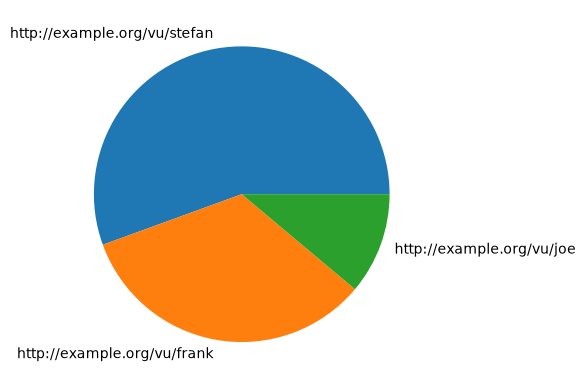

In [36]:
# Pandas visualization
courseload.set_index('teacher', inplace=True)
courseload['courses'].plot.pie()

## Task 4a (10 points): Make a horizontal bar chart (with suitable labels and title) from the `courseload` dataframe

There are many different kinds of plots that we can make. Please look at [the Pandas wiki](https://pandas.pydata.org/docs/user_guide/visualization.html) to get an idea on what is possible.

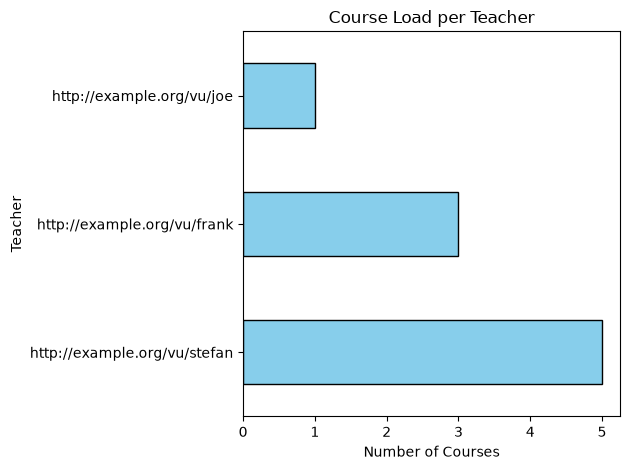

In [49]:
# Horizontal bar chart for the course-load dataframe
# Horizontal bar chart for the course-load dataframe
chart = courseload['courses'].plot.barh(color='skyblue', edgecolor='black')

plt.title('Course Load per Teacher')
plt.xlabel('Number of Courses')
plt.ylabel('Teacher')
plt.tight_layout()
plt.show()


## Task 4b (10 points): Write a new SPARQL query for DBpedia and create an interesting chart from it

In [56]:
#this querry gets the 10 countries in the world with the biggest population that start with the letter N. 


endpoint = "http://dbpedia.org/sparql"
query = """
PREFIX dbo: <http://dbpedia.org/ontology/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?countryLabel (MAX(?population) AS ?maxPopulation)
WHERE {
    ?country a dbo:Country ;
             dbo:populationTotal ?population ;
             rdfs:label ?countryLabel .

    FILTER(LANG(?countryLabel) = "en")
    FILTER(STRSTARTS(STR(?countryLabel), "N"))
    FILTER(isNumeric(?population))
}
GROUP BY ?countryLabel
ORDER BY DESC(?maxPopulation)
LIMIT 10
"""

#helper funcions are GOATed
pop_data = table_from_query(endpoint, query)

#And so are build in function(even if you have to import them)
pop_data["maxPopulation"] = pd.to_numeric(pop_data["maxPopulation"], errors="coerce")
pop_data = pop_data.dropna().head(10)

# Plot
chart = pop_data.plot.bar(
    x="countryLabel",
    y="maxPopulation",
    figsize=(12, 6),
    color="darkgreen",
    edgecolor="black"
)

chart.set_title("10 biggest countries that start with N")
chart.set_xlabel("Country")
chart.set_ylabel("Population")
chart.get_legend().remove()  # Remove legend as y-axis is clearly labeled
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

HTTPError: HTTP Error 503: Service Unavailable

## Task 5 (10 points). Conditional styling

Below is a query to find countries and their surface area in $m^2$. Below that is some code that adds some colour to the resulting table.


We ask you to update the query and code below to add a new column that shows the percentage of the country's area that is water.
The background color of this column must depend on this percentage: it should be greener if more of the country is land, and bluer if more of the country is water.

In [39]:
endpoint = "http://dbpedia.org/sparql"
query = """
PREFIX dbo: <http://dbpedia.org/ontology/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?name ?area_100k_km2 ?giniCoefficient ?water_pct
WHERE { 
    ?country 
        a dbo:Country ;
        dbo:area ?area ; # area is stated in m^2
        dbo:giniCoefficient ?giniCoefficient ;
        dbo:percentageOfAreaWater ?water_pct ;  
        rdfs:label ?name. 
    
    BIND (ROUND(?area/100000000000) AS ?area_100k_km2)
    FILTER(LANG(?name) = 'en')
}
ORDER BY DESC(?area_100k_km2)
LIMIT 50"""

dbpedia_countries = table_from_query(endpoint, query)

In [ ]:
# Styling: https://pandas.pydata.org/docs/user_guide/style.html
# Using CSS Hue-Saturation-Level colors: https://www.w3schools.com/colors/colors_hsl.asp

import pandas as pd

def gini_color(gini):
    return f'background: hsl({100 - gini}, 100%, 50%)'

def water_color(water_pct):
    #start at 120 as green with max 240 for more blue
    blueness = 120 + 3 * water_pct
    return f'background: hsl({blueness}, 100%, 50%)'

dbpedia_countries.style \
    .map(gini_color, subset=(slice(None), "giniCoefficient")) \
    .map(water_color, subset=(slice(None), "water_pct"))

,name,area_100k_km2,giniCoefficient,water_pct
0,Russia,171.000000,36.000000,13.000000
1,History of the Russian Federation,171.000000,36.000000,13.000000
2,Canada,100.000000,29.200001,11.760000
3,United States,98.000000,41.599998,7.000000
4,China,96.000000,35.700001,2.800000
5,Brazil,85.000000,51.599998,0.650000
6,Australia,77.000000,32.400002,1.790000
7,European Union,42.000000,29.600000,2.930000
8,India,33.000000,25.500000,9.600000
9,Argentina,28.000000,40.700001,1.570000


# Map Visualizations

Below is a query to find all EU capitals, together with their coordinates. The results are drawn on a map using the library `folium`. 

First run the following cells to install and import the library.

In [41]:
%pip install folium

Note: you may need to restart the kernel to use updated packages.


In [42]:
import folium

# Task 6 (20 points) - Population counts

We ask you to update the query and code below to make the markers (circles) scale with the population of the capital (but keep it readable!).

In [43]:
endpoint = "http://query.wikidata.org/sparql"
query = """
SELECT ?capitalLabel ?coords ?population
WHERE {
    ?country
        wdt:P463 wd:Q458 ; # member of: European Union
        wdt:P36 ?capital . # capital: ?capital

    ?capital
        wdt:P625 ?coords ; # coordinate location: ?coords
        wdt:P1082 ?population . # population: ?population

    # Using Wikidata-only label service
    SERVICE wikibase:label { bd:serviceParam wikibase:language "[AUTO_LANGUAGE],en". }
}"""

capitals = table_from_query(endpoint, query)

In [ ]:
# Extract latitude and longitude from coordinates in Well-Known Text (WKT) format
capitals_coords = capitals.join(capitals.coords.str.extract('Point\\((?P<lon>\\S+) (?P<lat>\\S+)\\)').astype(float))

#choose biggest statement of population per city
capitals_coords['population'] = capitals_coords['population'].astype(float)
capitals_coords = (capitals_coords
                   .sort_values('population', ascending=False)
                   .drop_duplicates(subset='capitalLabel')
                   .reset_index(drop=True))

#circle grows with the root of the increase in population
def population_radius(pop, min_r=4, max_r=30):
    return min_r + (max_r - min_r) * (pop / capitals_coords['population'].max()) ** 0.5

middle = [capitals_coords['lat'].mean(), capitals_coords['lon'].mean()]
m = folium.Map(location=middle, zoom_start=4)
for _, row in capitals_coords.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=population_radius(row['population']),
        popup=f"{row['capitalLabel']}: {int(row['population']):,}",
        color="#3186cc",
        fill=True,
        fill_color="#3186cc",
        fill_opacity=0.5,
    ).add_to(m)

# display map; the notebook needs to be trusted for this to work (file -> trust notebook OR view -> ActivateCommandPalette -> Trust Notebook)
m